# Run League: fitness estimate AI — build and test

This notebook builds the fitness estimate AI and tests whether it tracks each runner's fitness **better than not updating**. It reads the CSVs made by the data-prep notebook (`runs_tune.csv`, `runs_test.csv`).

**The model (two simple parts)**
1. **A general pace→heart-rate line**, fitted once across all tuning users: at a given pace and distance, what heart rate does a *typical* runner have?
2. **A per-user fitness offset**: how many bpm this runner sits below (fitter) or above (less fit) that line. It starts from the runner's first few runs and updates after every run.

**What it tests**
- Does updating beat two baselines (an average runner, and a score that never updates)?
- Exponential moving average vs Kalman filter.
- How many starting runs to use (1, 3, 5, 10) — *the data decides*.
- Turns the final score into a fitness number and training paces.

The error we measure is **heart-rate prediction error in bpm**: before each run, predict its average heart rate; compare with the real one. Lower is better.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Load the cleaned runs

In [2]:
from google.colab import drive
drive.mount('/content/drive')

DIR = '/content/drive/MyDrive/RunLeague/'
import pandas as pd, numpy as np

tune = pd.read_csv(DIR + 'runs_tune.csv', parse_dates=['date'])
test = pd.read_csv(DIR + 'runs_test.csv', parse_dates=['date'])
for df in (tune, test):
    df.sort_values(['user_id', 'date'], inplace=True)
    df.reset_index(drop=True, inplace=True)

print(f'Tune: {tune.user_id.nunique()} users, {len(tune):,} runs')
print(f'Test: {test.user_id.nunique()} users, {len(test):,} runs')
tune.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tune: 508 users, 55,469 runs
Test: 128 users, 13,225 runs


,user_id,workout_id,run_number,date,gender,distance_km,duration_min,pace_min_per_km,avg_hr
0,69,20253456,1,2011-08-24 02:31:53,male,5.460,29.82,5.461,157.9
1,69,24888434,2,2011-10-05 15:28:05,male,2.792,12.00,4.298,164.6
2,69,30369221,3,2011-12-04 16:51:20,male,2.788,11.67,4.185,174.8
3,69,596953078,4,2012-04-04 13:11:34,male,15.938,85.37,5.356,141.3
4,69,150501380,5,2013-01-11 12:01:37,male,18.641,113.30,6.078,143.0


## 2. The general pace→heart-rate line

Fitted once, on the tuning runs only. It learns the average runner:

```
heart_rate ≈ a + b · pace + c · distance
```

Distance is included because longer runs drift to a higher heart rate at the same pace; without it, a long run would look like a drop in fitness. We use a plain least-squares fit so every coefficient is explainable.

In [3]:
FEATURES = ['pace_min_per_km', 'distance_km']

def fit_line(df):
    X = np.column_stack([np.ones(len(df))] + [df[f].values for f in FEATURES])
    y = df['avg_hr'].values
    coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return coef   # [a, b_pace, c_distance]

def predict_typical(coef, df):
    X = np.column_stack([np.ones(len(df))] + [df[f].values for f in FEATURES])
    return X @ coef

coef = fit_line(tune)
print(f'heart_rate = {coef[0]:.1f} + {coef[1]:.2f}·pace + {coef[2]:.2f}·distance')

resid = tune['avg_hr'].values - predict_typical(coef, tune)
print(f'Residual spread (one run, average runner): {resid.std():.1f} bpm')
print('That spread is what the per-user fitness offset exists to explain.')

heart_rate = 173.1 + -3.99·pace + -0.08·distance
Residual spread (one run, average runner): 13.4 bpm
That spread is what the per-user fitness offset exists to explain.


## 3. The replay engine

For one user's runs in order, every method is the same shape: keep an **offset**, predict `typical + offset`, then update the offset. Only the update rule differs.

- **average** — offset always 0 (ignores who the runner is).
- **frozen** — offset set from the first `warmup` runs, then never changed.
- **ema** — offset nudged by `gain × error` after every run.
- **kalman** — offset tracked by a local-level filter: big steps early, smaller as confidence grows.

Scoring starts only after run `score_from`, so every method and every warm-up size is judged on the **same** runs.

In [4]:
def replay_user(runs, coef, method, warmup=5, gain=0.15, Q=0.5, R=50.0, score_from=0):
    typ = predict_typical(coef, runs)
    hr = runs['avg_hr'].values
    n = len(runs)

    # Starting offset = how far this runner sat from the line over their first `warmup` runs
    w = min(warmup, n)
    start_offset = float(np.mean(hr[:w] - typ[:w]))

    offset = 0.0 if method == 'average' else start_offset
    P = 1000.0                      # Kalman: start unsure
    errors = []
    for i in range(n):
        pred = typ[i] + offset
        if i >= score_from:
            errors.append(abs(hr[i] - pred))
        err = hr[i] - pred          # signed, for the update
        if method == 'ema':
            offset += gain * err
        elif method == 'kalman':
            P += Q                   # fitness may have drifted since last run
            K = P / (P + R)
            offset += K * err
            P *= (1 - K)
        # 'average' and 'frozen' never update
    return errors

def evaluate(df, coef, method, score_from=5, **kw):
    """Mean abs error per user, then averaged across users (±standard error)."""
    per_user = []
    for _, runs in df.groupby('user_id'):
        if len(runs) <= score_from:
            continue
        e = replay_user(runs, coef, method, score_from=score_from, **kw)
        if e:
            per_user.append(np.mean(e))
    per_user = np.array(per_user)
    return per_user.mean(), per_user.std() / np.sqrt(len(per_user)), len(per_user)

## 4. Tune the settings on the tuning users

Pick the EMA gain and the Kalman noise ratio that give the lowest error on the tuning users. These are the only knobs; everything else is fixed.

In [5]:
# EMA: try a range of gains
gains = [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]
ema_scores = [(g, evaluate(tune, coef, 'ema', gain=g)[0]) for g in gains]
best_gain = min(ema_scores, key=lambda t: t[1])[0]
print('EMA gain tuning:')
for g, s in ema_scores:
    print(f'  gain {g:<4}: {s:.2f} bpm' + ('   <- best' if g == best_gain else ''))

# Kalman: R fixed at the run-to-run noise; sweep Q (how fast fitness drifts)
R_fixed = float((resid.std())**2)
Qs = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0]
kal_scores = [(q, evaluate(tune, coef, 'kalman', Q=q, R=R_fixed)[0]) for q in Qs]
best_Q = min(kal_scores, key=lambda t: t[1])[0]
print(f'\nKalman Q tuning (R fixed at {R_fixed:.0f}):')
for q, sc in kal_scores:
    print(f'  Q {q:<5}: {sc:.2f} bpm' + ('   <- best' if q == best_Q else ''))
if best_Q == Qs[-1]:
    print('NOTE: best Q is at the top of the range — widen Qs and rerun to confirm.')

EMA gain tuning:
  gain 0.05: 7.06 bpm
  gain 0.1 : 6.90 bpm
  gain 0.15: 6.86 bpm   <- best
  gain 0.2 : 6.87 bpm
  gain 0.3 : 6.95 bpm
  gain 0.5 : 7.27 bpm

Kalman Q tuning (R fixed at 178):
  Q 0.05 : 7.07 bpm
  Q 0.1  : 7.04 bpm
  Q 0.25 : 6.99 bpm
  Q 0.5  : 6.95 bpm
  Q 1.0  : 6.90 bpm
  Q 2.0  : 6.87 bpm
  Q 4.0  : 6.86 bpm   <- best
  Q 8.0  : 6.87 bpm
  Q 16.0 : 6.91 bpm


## 5. The main result — on the test users

The tuned settings are now run **once** on the 128 test users the AI never saw. This is the table for your report.

In [6]:
methods = [
    ('Average runner (ignores the person)', 'average', {}),
    ('Never updates (frozen after warm-up)', 'frozen', {}),
    (f'Moving average (gain {best_gain})',    'ema',    {'gain': best_gain}),
    (f'Kalman filter (Q {best_Q})',           'kalman', {'Q': best_Q, 'R': R_fixed}),
]

print(f'{"Method":<40}{"Error (bpm)":>14}{"Users":>8}')
print('-' * 62)
results = {}
for label, m, kw in methods:
    mean, se, n = evaluate(test, coef, m, **kw)
    results[label] = mean
    print(f'{label:<40}{mean:>7.2f} ± {se:.2f}{n:>8}')

best = min(results.values())
print('\nLower is better. If the updating methods beat "Never updates",')
print('the fitness estimate is learning something real about each runner.')

Method                                     Error (bpm)   Users
--------------------------------------------------------------
Average runner (ignores the person)       11.44 ± 0.49     128
Never updates (frozen after warm-up)       8.67 ± 0.34     128
Moving average (gain 0.15)                 7.15 ± 0.24     128
Kalman filter (Q 4.0)                      7.15 ± 0.24     128

Lower is better. If the updating methods beat "Never updates",
the fitness estimate is learning something real about each runner.


## 6. How many starting runs? Let the data decide

Each warm-up size is scored on the **same** runs (from run 11 onward), so the comparison is fair. Users with fewer than 11 runs sit out this test only.

In [7]:
print(f'{"Warm-up runs":<16}{"Frozen":>12}{"Kalman":>12}')
print('-' * 40)
for w in [1, 3, 5, 10]:
    froz = evaluate(test, coef, 'frozen', warmup=w, score_from=10)[0]
    kal  = evaluate(test, coef, 'kalman', warmup=w, Q=best_Q, R=R_fixed, score_from=10)[0]
    print(f'{w:<16}{froz:>12.2f}{kal:>12.2f}')
print('\nFrozen improves with more warm-up runs (a steadier starting score).')
print('Kalman barely cares: it corrects a rough start within a few runs on its own,')
print('so your app need not make users wait before personalising paces.')

Warm-up runs          Frozen      Kalman
----------------------------------------
1                      10.98        7.22
3                       9.14        7.22
5                       8.89        7.22
10                      8.34        7.22

Frozen improves with more warm-up runs (a steadier starting score).
Kalman barely cares: it corrects a rough start within a few runs on its own,
so your app need not make users wait before personalising paces.


## 7. One runner's fitness over time

The fitness score is **how many bpm below a typical runner** someone sits at the same paces — higher is fitter. This is the raw offset, so it never extrapolates. We take a clearly-improving runner (75th percentile of improvement, not the single biggest swing, which is usually noise) and plot it run by run. Below the chart it is also translated into the intuitive "pace at 150 bpm", clamped to a realistic range.

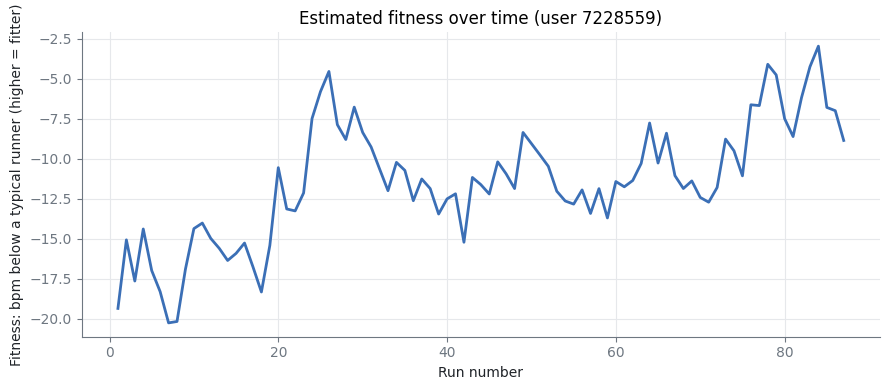

Fitness score: -19.3 -> -8.9 bpm vs a typical runner
Equivalent pace at 150 bpm: 10.43 -> 7.80 min/km (lower = fitter)


In [8]:
REF_HR, REF_DIST = 150.0, 10.0
PACE_BOUNDS = (2.75, 12.0)   # realistic running paces; the display pace is clamped to this

def pace_at_ref(offset):
    # Solve typical(pace) + offset = REF_HR for pace, at the reference distance.
    # The pooled pace slope is shallow, so large offsets extrapolate to silly paces —
    # clamp the DISPLAY pace. The offset itself (bpm) is the real, unclamped score.
    a, b, c = coef
    pace = (REF_HR - offset - a - c * REF_DIST) / b
    return float(np.clip(pace, *PACE_BOUNDS))

def offset_track(runs):
    """The fitness score run by run, as 'bpm below a typical runner' (higher = fitter)."""
    typ = predict_typical(coef, runs); hr = runs['avg_hr'].values
    offset = float(np.mean((hr - typ)[:5])); P = 1000.0; out = []
    for i in range(len(runs)):
        P += best_Q; K = P / (P + R_fixed)
        offset += K * (hr[i] - (typ[i] + offset)); P *= (1 - K)
        out.append(-offset)          # negate: higher = fitter
    return np.array(out)

import matplotlib.pyplot as plt
INK, MUTED, LINE = '#1f2328', '#6e7781', '#3b6fb6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.labelcolor': INK, 'axes.grid': True, 'grid.color': '#e6e8eb'})

# Pick a clearly-improving but not extreme runner: 75th percentile of improvement,
# not the single biggest swing (which is usually an artifact).
cands = [u for u, r in test.groupby('user_id') if len(r) >= 40]
tracks = {u: offset_track(test[test.user_id == u]) for u in cands}
improve = {u: tracks[u][-1] - tracks[u][0] for u in cands}   # positive = got fitter
who = sorted(cands, key=lambda u: improve[u])[int(len(cands) * 0.75)]
track = tracks[who]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(track) + 1), track, color=LINE, linewidth=2)
ax.set(title=f'Estimated fitness over time (user {who})',
       xlabel='Run number', ylabel='Fitness: bpm below a typical runner (higher = fitter)')
ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# Translate the ends into the intuitive 'pace at 150 bpm' metric (clamped).
p0, p1 = pace_at_ref(-track[0]), pace_at_ref(-track[-1])
print(f'Fitness score: {track[0]:+.1f} -> {track[-1]:+.1f} bpm vs a typical runner')
print(f'Equivalent pace at 150 bpm: {p0:.2f} -> {p1:.2f} min/km (lower = fitter)')

## 8. Turn a score into training paces

How your app converts a runner's current estimate into (a) a friendly 0-100 fitness number for the user to see, and (b) the paces the fitness-plan AI uses. The 0-100 score is cosmetic — the AI still runs on the raw bpm offset underneath.

In [9]:
SCORE_SPAN = 35.0   # bpm; offsets beyond ±this map to 0 / 100

def display_score(offset):
    """Turn the raw bpm offset into a friendly 0-100 number (higher = fitter).
    offset -35 bpm -> 100, 0 -> 50, +35 -> 0. Cosmetic only; the AI runs in bpm."""
    return round(float(np.clip(100 - (offset + SCORE_SPAN) / (2 * SCORE_SPAN) * 100, 0, 100)))

def training_paces(offset):
    base = pace_at_ref(offset)          # already clamped to a realistic range
    return {
        'easy':      round(base + 0.6, 2),
        'long':      round(base + 0.5, 2),
        'tempo':     round(base - 0.4, 2),
        'intervals': round(base - 0.8, 2),
    }

demo = float(np.mean((test['avg_hr'].values - predict_typical(coef, test))[:5]))
print(f'Example runner: offset {demo:+.1f} bpm  ->  display score {display_score(demo)}/100')
print('Paces (min/km):', training_paces(demo))

# Where typical runners land on the 0-100 scale, from the real spread
off_all = pd.concat([tune, test]).assign(
    r=lambda d: d['avg_hr'] - predict_typical(coef, d)).groupby('user_id')['r'].mean()
print()
print('Display score across users (higher = fitter):',
      f'5th pct {display_score(off_all.quantile(.95))},',
      f'median {display_score(off_all.median())},',
      f'95th pct {display_score(off_all.quantile(.05))}')

Example runner: offset +10.6 bpm  ->  display score 35/100
Paces (min/km): {'easy': 8.85, 'long': 8.75, 'tempo': 7.85, 'intervals': 7.45}

Display score across users (higher = fitter): 5th pct 24, median 47, 95th pct 69


## 9. Save the settings for the app

In [10]:
import json
settings = {
    'line': {'intercept': round(float(coef[0]), 3),
             'pace_coef': round(float(coef[1]), 3),
             'distance_coef': round(float(coef[2]), 3)},
    'kalman': {'Q': best_Q, 'R': round(R_fixed, 1), 'P0': 1000.0},
    'ema_gain': best_gain,
    'warmup_runs': 5,
    'reference': {'hr': REF_HR, 'distance_km': REF_DIST},
    'display_score_span_bpm': SCORE_SPAN,   # offset ±this -> 0/100 for the user-facing number
}
with open(DIR + 'fitness_estimate_settings.json', 'w') as f:
    json.dump(settings, f, indent=2)
print(json.dumps(settings, indent=2))
print('\nSaved. Port these into FitnessEstimateService.js in your backend.')

{
  "line": {
    "intercept": 173.065,
    "pace_coef": -3.993,
    "distance_coef": -0.076
  },
  "kalman": {
    "Q": 4.0,
    "R": 178.4,
    "P0": 1000.0
  },
  "ema_gain": 0.15,
  "warmup_runs": 5,
  "reference": {
    "hr": 150.0,
    "distance_km": 10.0
  },
  "display_score_span_bpm": 35.0
}

Saved. Port these into FitnessEstimateService.js in your backend.


## What to take to your report

- The **test-user table** (section 5): updating vs not updating. Use these numbers.
- The **warm-up table** (section 6): your evidence for how many starting runs, instead of guessing.
- The **fitness-over-time chart** (section 7): a clear visual for your presentation.
- The **settings file** (section 9): the tuned numbers your app actually uses.

**State honestly:** this tests heart-rate prediction, which is evidence the score tracks fitness, not direct proof of race times. Test runners are more experienced than typical app users, and temperature and hills are not accounted for in this data.